In [12]:
import sys; sys.path.append("..")
import ee, config
from src.landsat_utils import summer_lst, lst_collection

ee.Initialize(project=config.GEE_PROJECT)
aoi = ee.Geometry.Rectangle(config.AOI_BBOX)

In [13]:
years = range(2018, 2026)
lst = ee.ImageCollection(
  [summer_lst(aoi, y, months=("05-15", "09-15")) for y in range(2018, 2026)]
).mean().rename("LST")
stats = lst.reduceRegion(
  ee.Reducer.percentile([5, 50, 95]).combine(ee.Reducer.mean(), sharedInputs=True),
  aoi, 100, maxPixels=1e9).getInfo()
stats

{'LST_mean': 29.112868831996337,
 'LST_p5': 24.13193562083381,
 'LST_p50': 28.873177298317778,
 'LST_p95': 35.121354768341725}

In [14]:
wc = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map").clip(aoi)

res = lst.addBands(wc).reduceRegion(
  ee.Reducer.mean().group(groupField=1, groupName="class"),
  aoi, 30, maxPixels=1e10, tileScale=4).getInfo()

names = {10: "Tree cover",  90: "Herbaceous wetland", 20: "Shrubland", 30: "Grassland", 40: "Cropland",
       50: "Built-up", 60: "Bare", 80: "Water"}
import pandas as pd
lst_by_class = (pd.DataFrame(res["groups"])
              .assign(class_name=lambda d: d["class"].map(names))
              .set_index("class_name")["mean"].round(1).sort_values())
lst_by_class

class_name
Tree cover            26.8
Herbaceous wetland    27.4
Water                 27.6
Grassland             30.3
Cropland              31.3
Bare                  31.5
Built-up              34.0
Name: mean, dtype: float64

In [15]:
import requests, pathlib
out = pathlib.Path("../data/processed/lst_summer_2018_2025.tif")
url = lst.toFloat().getDownloadURL({"region": aoi, "scale": 100,
                                  "crs": config.CRS, "format": "GEO_TIFF"})
out.write_bytes(requests.get(url, timeout=300).content)
out.stat().st_size / 1e6  # MB


0.444606

In [16]:
pop = ee.Image("JRC/GHSL/P2023A/GHS_POP/2020").select("population_count")
proj = pop.projection()  # 100 m

# LST at the 100 m population grid (mean of 30 m pixels)
lst100 = (lst.reproject("EPSG:32632", None, 30)
    .reduceResolution(ee.Reducer.mean(), maxPixels=1024)
    .reproject(proj))

p90 = lst100.reduceRegion(ee.Reducer.percentile([90]), aoi, 100,
                    maxPixels=1e10, tileScale=4).getInfo()["LST"]

hot = lst100.gte(p90)
pop_v = pop.updateMask(lst100.mask())   # only people where LST exists
tot = pop_v.reduceRegion(ee.Reducer.sum(), aoi, 100, maxPixels=1e10,
tileScale=4).getInfo()["population_count"]
hot_pop = pop_v.updateMask(hot).reduceRegion(ee.Reducer.sum(), aoi, 100, maxPixels=1e10,
tileScale=4).getInfo()["population_count"]
t2 = (ee.ImageCollection("LANDSAT/LC08/C02/T2_L2").filterBounds(aoi)
    .filterDate("2018-05-15", "2025-09-15").select("ST_B10").count().clip(aoi))
u = t2.visualize(min=0, max=40, palette=["white", "orange", "green"]).getThumbURL(
  {"region": aoi, "dimensions": 600, "format": "png"})
print(f"p90 threshold: {p90:.1f} °C")
print(f"Population in AOI: {tot:,.0f}")
print(f"Population in hotspots: {hot_pop:,.0f} ({hot_pop/tot:.0%})")

p90 threshold: 33.9 °C
Population in AOI: 1,081,269
Population in hotspots: 574,031 (53%)



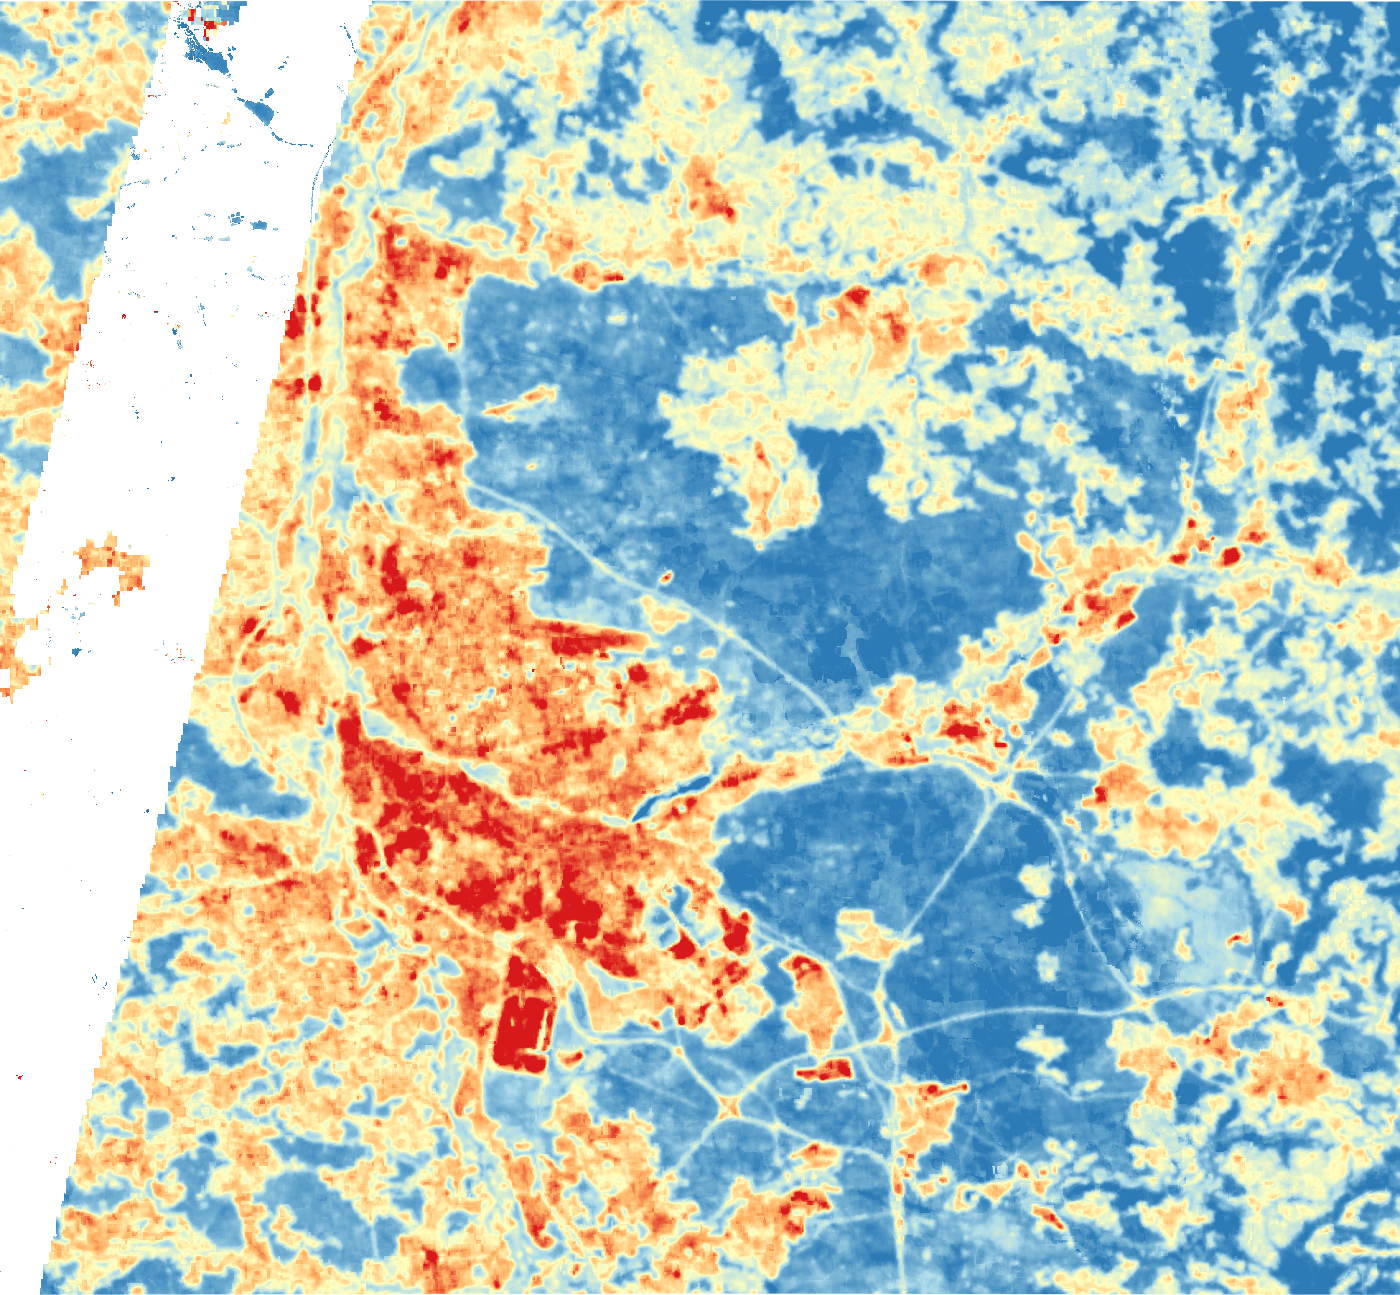

In [17]:
import pandas as pd, requests, pathlib
from src.webmap import overlay_map, gradient_legend

pd.DataFrame({
  "metric": ["p90_threshold_C", "pop_aoi", "pop_hotspots", "share_hotspots"],
  "value": [round(p90, 1), round(tot), round(hot_pop), round(hot_pop / tot, 3)],
}).to_csv("../data/processed/heat_summary.csv", index=False)
pd.DataFrame({"class": lst_by_class.index, "mean_LST_C": lst_by_class.values}) \
.to_csv("../data/processed/lst_by_landcover.csv", index=False)

palette = ["#2c7bb6", "#abd9e9", "#ffffbf", "#fdae61", "#d7191c"]
vmin, vmax = 24, 38
png = pathlib.Path("../figures/lst_summer_map.png")
url = lst.visualize(min=vmin, max=vmax, palette=palette).getThumbURL(
  {"region": aoi, "dimensions": 1400, "crs": "EPSG:3857", "format": "png"})
png.write_bytes(requests.get(url, timeout=300).content)

w, s, e, n = config.AOI_BBOX
legend = gradient_legend("Summer LST 2018–2025 (°C)", palette, vmin, vmax, "cooler", "hotter")
overlay_map(png, [[s, w], [n, e]], "Summer LST", legend, "../figures/lst_summer_map.html")

In [18]:
import requests, pathlib
d = pathlib.Path("../figures/diag"); d.mkdir(exist_ok=True)
raw = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2").filterBounds(aoi)
     .filterDate("2018-05-15", "2025-09-15").select("ST_B10").count().clip(aoi))
valid = lst_collection(aoi, "2018-05-15", "2025-09-15").count().clip(aoi)
for name, img in [("raw", raw), ("valid", valid)]:
  u = img.visualize(min=0, max=40, palette=["white", "orange", "green"]).getThumbURL(
      {"region": aoi, "dimensions": 600, "format": "png"})
  (d / f"{name}.png").write_bytes(requests.get(u, timeout=300).content)

In [12]:
from src.landsat_utils import lst_collection
col = lst_collection(aoi, "2018-05-15", "2025-09-15").filter(
  ee.Filter.calendarRange(5, 9, "month"))
n_obs = col.count().clip(aoi)
url = n_obs.visualize(min=0, max=40, palette=["white", "orange", "green"]).getThumbURL(
  {"region": aoi, "dimensions": 800, "format": "png"})
from IPython.display import Image; Image(url=url)

In [18]:
t2 = (ee.ImageCollection("LANDSAT/LC08/C02/T2_L2").filterBounds(aoi)
    .filterDate("2018-05-15", "2025-09-15").select("ST_B10").count().clip(aoi))
u = t2.visualize(min=0, max=40, palette=["white", "orange", "green"]).getThumbURL(
  {"region": aoi, "dimensions": 600, "format": "png"})
requests.get(u, timeout=300).content
(d / "t2.png").write_bytes(requests.get(u, timeout=300).content)

5649